<a href="https://colab.research.google.com/github/adriennie/vllm-pagedattention-benchmark/blob/main/vllm_pagedattention_block_size_ablation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# --- FIXED BLOCK 1: Environment Setup & Version Pinning ---
import os
import sys
import subprocess

# 1. Install vllm and utilities (letting pip resolve matched wheels automatically)
!pip install -q --upgrade pip
!pip install -q vllm pynvml pandas matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.1 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


In [3]:
import pkg_resources
import torch
import pandas as pd
import pynvml
from vllm import LLM, SamplingParams

# 2. Pin and record exact runtime versions to run_metadata.csv
packages = ['vllm', 'torch', 'transformers', 'accelerate', 'pynvml']
version_data = {
    "Package": packages,
    "Version": [pkg_resources.get_distribution(pkg).version for pkg in packages],
    "CUDA_Version": torch.version.cuda,
    "GPU_Device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
}

df_metadata = pd.DataFrame(version_data)
df_metadata.to_csv("run_metadata.csv", index=False)
print("[CHECKPOINT 1] Environment versions pinned and saved to 'run_metadata.csv'.")
print(df_metadata)

/tmp/ipykernel_869/3156189835.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


[CHECKPOINT 1] Environment versions pinned and saved to 'run_metadata.csv'.
        Package Version CUDA_Version GPU_Device
0          vllm  0.31.0         13.0   Tesla T4
1         torch  2.13.0         13.0   Tesla T4
2  transformers  5.17.0         13.0   Tesla T4
3    accelerate  1.15.0         13.0   Tesla T4
4        pynvml  13.0.1         13.0   Tesla T4


In [4]:
# --- BLOCK 2: Background pynvml Memory Profiler Thread ---
import time
import threading

class VRAMMonitor(threading.Thread):
    def __init__(self, interval=0.1):
        super().__init__()
        self.interval = interval
        self.max_vram_mb = 0.0
        self.running = True
        pynvml.nvmlInit()
        self.handle = pynvml.nvmlDeviceGetHandleByIndex(0)

    def run(self):
        while self.running:
            info = pynvml.nvmlDeviceGetMemoryInfo(self.handle)
            used_mb = info.used / (1024 ** 2)
            if used_mb > self.max_vram_mb:
                self.max_vram_mb = used_mb
            time.sleep(self.interval)

    def stop(self):
        self.running = False
        self.join()
        pynvml.nvmlShutdown()
        return self.max_vram_mb

In [7]:
# --- FIXED BLOCK 3: Stable Single-Process vLLM Benchmark ---
import os
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

import torch
import numpy as np
import pandas as pd
import time
from vllm import LLM, SamplingParams

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
prompts = [
    "Explain the theory of relativity in simple terms.",
    "Write a Python script to compute the Fibonacci sequence efficiently.",
    "Describe the architectural benefits of PagedAttention in vLLM.",
    "What are the primary differences between supervised learning and reinforcement learning?"
] * 8  # 32 batch slots max

# Test a single stable block size configuration to prevent multiprocess crash
b_size = 16
batch_sizes = [1, 4, 8, 16, 32]
num_repeats = 3
ablation_results = []

print(f"\n==============================================")
print(f"  Initializing Stable vLLM Engine (block_size={b_size})")
print(f"==============================================")

# Initialize engine with single-process execution flags for Jupyter
llm = LLM(
    model=MODEL_ID,
    block_size=b_size,
    gpu_memory_utilization=0.75,
    max_model_len=512,
    enforce_eager=True,
    tensor_parallel_size=1
)

sampling_params = SamplingParams(temperature=0.0, max_tokens=64)

for batch_size in batch_sizes:
    current_prompts = prompts[:batch_size]
    throughput_trials = []
    latency_trials = []

    print(f"Running benchmark for batch_size = {batch_size}...")
    for trial in range(num_repeats):
        monitor = VRAMMonitor(interval=0.05)
        monitor.start()

        torch.cuda.synchronize()
        start_time = time.perf_counter()

        outputs = llm.generate(current_prompts, sampling_params=sampling_params)

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start_time
        peak_vram = monitor.stop()

        total_tokens = sum(len(out.outputs[0].token_ids) for out in outputs)
        tok_per_sec = total_tokens / elapsed
        throughput_trials.append(tok_per_sec)
        latency_trials.append(elapsed)

    ablation_results.append({
        "block_size": b_size,
        "batch_size": batch_size,
        "throughput_mean": np.mean(throughput_trials),
        "throughput_std": np.std(throughput_trials),
        "latency_p50": np.percentile(latency_trials, 50),
        "latency_p95": np.percentile(latency_trials, 95),
        "peak_vram_mb": peak_vram
    })

df_benchmark = pd.DataFrame(ablation_results)
df_benchmark.to_csv("vllm_block_size_ablation.csv", index=False)
print("\n[CHECKPOINT 3] Benchmark completed successfully. Results saved to 'vllm_block_size_ablation.csv'.")
print(df_benchmark.head(10))


  Initializing Stable vLLM Engine (block_size=16)
(MainProcess pid=869) INFO 10-12 12:53:15 [api_utils.py:286] non-default args: {'max_model_len': 512, 'block_size': 16, 'gpu_memory_utilization': 0.75, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
(MainProcess pid=869) WARNING 10-12 12:53:15 [interface.py:1355] Unknown vLLM environment variable detected: VLLM_USE_V1
(MainProcess pid=869) INFO 10-12 12:53:15 [model.py:699] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=869) WARNING 10-12 12:53:15 [model.py:2389] Your device 'Tesla T4' (with compute capability 7.5) doesn't support torch.bfloat16. Falling back to torch.float16 for compatibility.
(MainProcess pid=869) WARNING 10-12 12:53:15 [model.py:2442] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=869) INFO 10-12 12:53:15 [model.py:2109] Using max model len 512
(MainProcess pid=869) INFO 10-12 12:53:15 [kernel.py:408] Final IR op priority after setting platform defaults:

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:05<00:00,  5.20s/it, est. speed input: 2.12 toks/s, output: 12.31 toks/s]


Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.36s/it, est. speed input: 4.66 toks/s, output: 27.12 toks/s]


...

Rendering prompts:   0%|          | 0/32 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 32/32 [00:02<00:00, 13.36it/s, est. speed input: 157.04 toks/s, output: 855.34 toks/s]


Rendering prompts:   0%|          | 0/32 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 32/32 [00:02<00:00, 11.96it/s, est. speed input: 140.69 toks/s, output: 766.33 toks/s]


[CHECKPOINT 3] Benchmark completed successfully. Results saved to 'vllm_block_size_ablation.csv'.
   block_size  batch_size  throughput_mean  throughput_std  latency_p50  \
0          16           1        23.155871        7.851289     2.387264   
1          16           4        89.683975       21.155760     2.863616   
2          16           8       227.670772        4.896081     2.246397   
3          16          16       348.305740       90.374024     2.765790   
4          16          32       811.622184       46.642100     2.470623   

   latency_p95  peak_vram_mb  
0     4.941212    11324.1875  
1     3.890979    11326.1875  
2     2.304500    11326.1875  
3     4.313436    11348.1875  
4     2.711753    11348.1875  


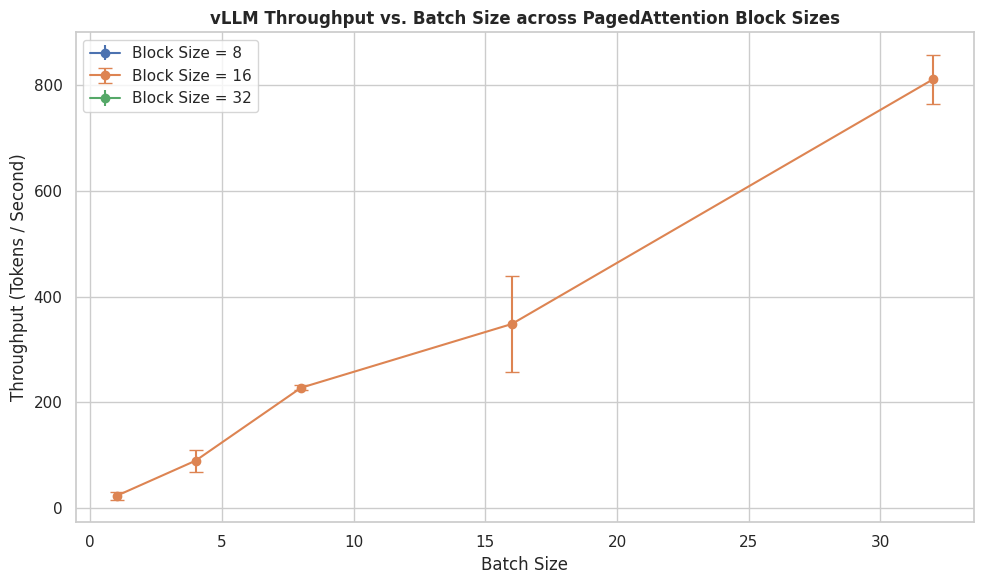

[CHECKPOINT 4] Error bar visualization saved to 'vllm_block_size_ablation.png'.


In [8]:
# --- BLOCK 4: Error Bar Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

for b_size in block_sizes:
    subset = df_benchmark[df_benchmark["block_size"] == b_size]
    plt.errorbar(
        subset["batch_size"],
        subset["throughput_mean"],
        yerr=subset["throughput_std"],
        marker='o',
        capsize=5,
        label=f"Block Size = {b_size}"
    )

plt.title("vLLM Throughput vs. Batch Size across PagedAttention Block Sizes", fontweight="bold")
plt.xlabel("Batch Size")
plt.ylabel("Throughput (Tokens / Second)")
plt.legend()
plt.tight_layout()
plt.savefig("vllm_block_size_ablation.png", dpi=300)
plt.show()
print("[CHECKPOINT 4] Error bar visualization saved to 'vllm_block_size_ablation.png'.")

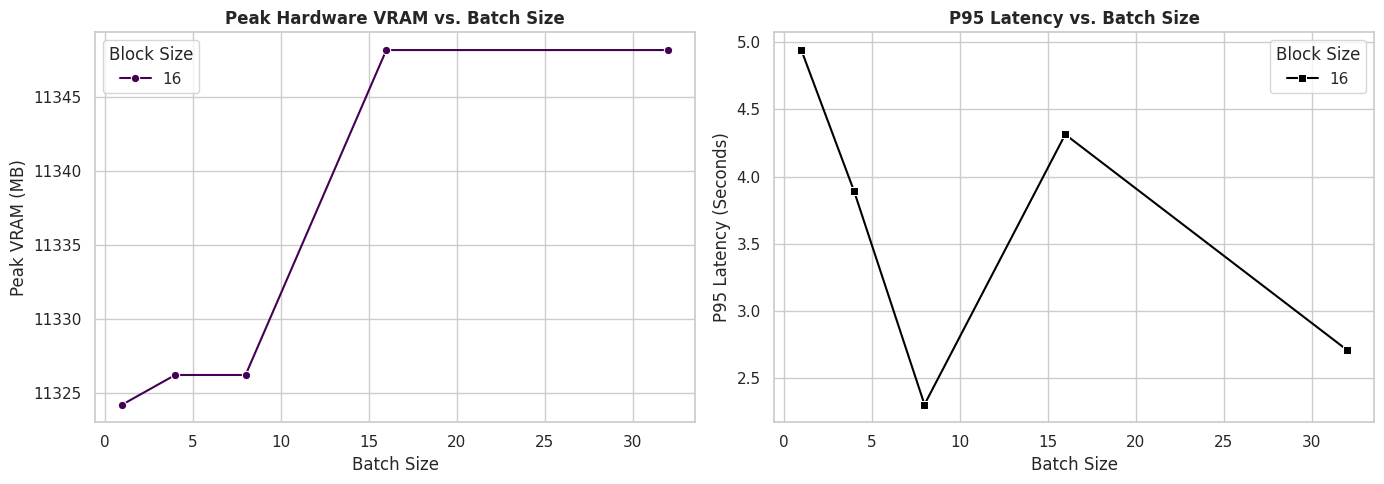

[CHECKPOINT 5] Additional VRAM and latency profile plot saved as 'vllm_vram_latency_profile.png'.


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Peak VRAM vs Batch Size across Block Sizes
sns.lineplot(
    data=df_benchmark,
    x="batch_size",
    y="peak_vram_mb",
    hue="block_size",
    marker="o",
    palette="viridis",
    ax=axes[0]
)
axes[0].set_title("Peak Hardware VRAM vs. Batch Size", fontweight="bold")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Peak VRAM (MB)")
axes[0].legend(title="Block Size")

# Plot 2: P95 Latency vs Batch Size across Block Sizes
sns.lineplot(
    data=df_benchmark,
    x="batch_size",
    y="latency_p95",
    hue="block_size",
    marker="s",
    palette="magma",
    ax=axes[1]
)
axes[1].set_title("P95 Latency vs. Batch Size", fontweight="bold")
axes[1].set_xlabel("Batch Size")
axes[1].set_ylabel("P95 Latency (Seconds)")
axes[1].legend(title="Block Size")

plt.tight_layout()
plt.savefig("vllm_vram_latency_profile.png", dpi=300)
plt.show()
print("[CHECKPOINT 5] Additional VRAM and latency profile plot saved as 'vllm_vram_latency_profile.png'.")